In [1]:
# mamba activate spatiocore_spatial_env
import tifffile
import os
from spatialdata.models import Image2DModel
import spatialdata_io
import pandas as pd
import geopandas as gpd
from shapely.geometry import Point
import numpy as np
from spatialdata.models import ShapesModel
import anndata
import scanpy as sc
from spatialdata import SpatialData
from spatialdata import polygon_query
from spatialdata import bounding_box_query
# from napari_spatialdata import Interactive
from spatialdata.models import TableModel
from spatialdata_plot.pl.utils import set_zero_in_cmap_to_transparent
from spatialdata import SpatialData
from napari.utils.colormaps import Colormap
from napari_spatialdata import Interactive
import spatialdata as sd
from scipy import ndimage as ndi
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib as mpl
import pickle

from spatialdata.transformations import (
    BaseTransformation,
    Identity,
    Sequence,
    align_elements_using_landmarks,
    get_transformation,
    set_transformation,
    Affine
)

/vf/users/kanferg/conda_v1/envs/spatialdata_env/lib/python3.12/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(
/vf/users/kanferg/conda_v1/envs/spatialdata_env/lib/python3.12/site-packages/xarray_schema/__init__.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFound, get_distribution
/vf/users/kanferg/conda_v1/envs/spatialdata_env/lib/python3.12/site-packages/anndata/__init__.py:44: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_text instead

In [2]:
import pickle
import sys


sys.path.insert(
    0,
    "/data/kanferg/Sptial_Omics/projects/NguyenLab/neuroblastoma"
)

from helper.utils import add_cluster_from_pickle
from helper.high_res_plot import PunchPlotter

In [3]:
pathad = '/data/HiTIF/data/spatialomics/neuroblastoma/data/andata_orig'
andata = sc.read_h5ad(os.path.join(pathad, "adata_nb_processed_v1.h5ad"))

In [4]:
annotation_colors = {
    "DISCARD": "#F2F2F2",

    # NB / tumor states: all gray for now
    "Adrenergic_Proliferating_NB": "#EDDE0C",
    "Transitional_NB": "#5E672A",
    "Adrenergic_StemLike_NB": "#7EFA02",
    "Adrenergic_Cycling_NB": "#CDC820",
    "Adrenergic_MYCNHigh_Metabolic_NB": "#D8A10A",
    "Mesenchymal_NB": "#11D167",

    # Non-NB compartments
    "Schwann_CAF": "#C49A6C",
    "M2_TAM": "#4292C6",
    "CD8_Cytotoxic_TCell_PartiallyExhausted": "#D62728",
    "MonocyteDerived_TissueResident_Macrophage": "#08519C",
    "Endothelial": "#17BECF",
    "Adrenocortical_Steroidogenic": "#F16913",
}

In [5]:
map_annotation = dict(zip(andata.obs['cell_id'], andata.obs["annotation_v1"]))

In [6]:
path_zarr = '/data/HiTIF/data/spatialomics/neuroblastoma/data/SCAF4480/PrimaryAnalysisOutput/SCAF4480_PA_xenium/nb_orig_label_v1.zarr'
sdata = sd.read_zarr(path_zarr)

version mismatch: detected: RasterFormatV02, requested: FormatV04


/vf/users/kanferg/conda_v1/envs/spatialdata_env/lib/python3.12/site-packages/zarr/creation.py:610: UserWarning: ignoring keyword argument 'read_only'
  compressor, fill_value = _kwargs_compat(compressor, fill_value, kwargs)
/vf/users/kanferg/conda_v1/envs/spatialdata_env/lib/python3.12/site-packages/zarr/creation.py:610: UserWarning: ignoring keyword argument 'read_only'
  compressor, fill_value = _kwargs_compat(compressor, fill_value, kwargs)
/vf/users/kanferg/conda_v1/envs/spatialdata_env/lib/python3.12/site-packages/zarr/creation.py:610: UserWarning: ignoring keyword argument 'read_only'
  compressor, fill_value = _kwargs_compat(compressor, fill_value, kwargs)
/vf/users/kanferg/conda_v1/envs/spatialdata_env/lib/python3.12/site-packages/zarr/creation.py:610: UserWarning: ignoring keyword argument 'read_only'
  compressor, fill_value = _kwargs_compat(compressor, fill_value, kwargs)
/vf/users/kanferg/conda_v1/envs/spatialdata_env/lib/python3.12/site-packages/zarr/creation.py:610: UserW

In [34]:
import importlib
import helper.high_res_plot as high_res_plot
importlib.reload(high_res_plot)
PunchPlotter = high_res_plot.PunchPlotter


sdata_obj = PunchPlotter(sdata = sdata,element_name = '21')

/vf/users/kanferg/conda_v1/envs/spatiocore_spatial_env/lib/python3.11/functools.py:909: UserWarning: The object has `points` element. Depending on the number of points, querying MAY suffer from performance issues. Please consider filtering the object before calling this function by calling the `subset()` method of `SpatialData`.
  return dispatch(args[0].__class__)(*args, **kw)


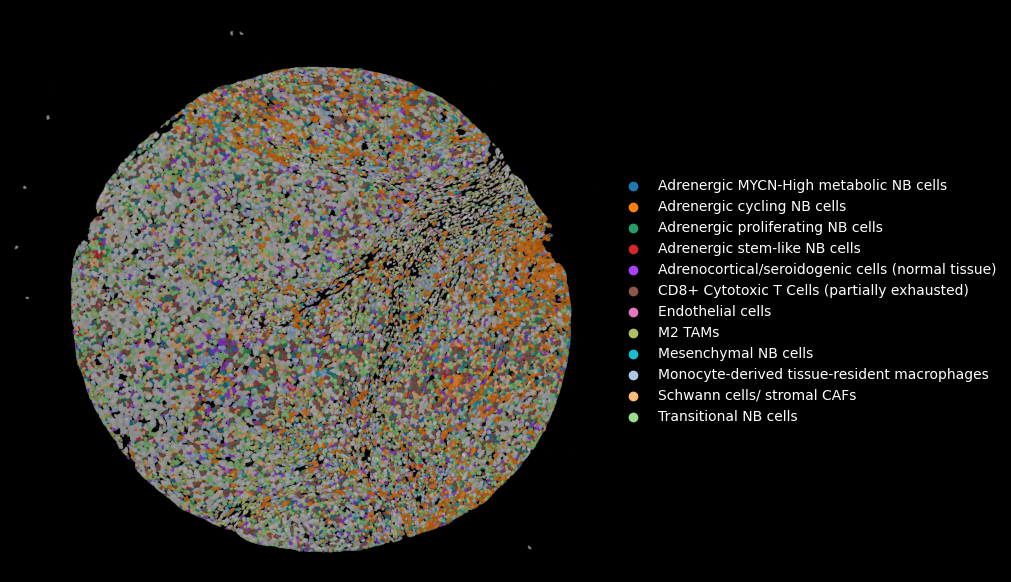

In [35]:
sdata_obj.plot_punch(
    colname="annotation_v1",
    colname_map=map_annotation,
    palette=annotation_colors,
)